#Motorpy

In [25]:
pip install rocketpy

### 1. Constantes Físicas y Propelente (`KNSB`)

Esta sección centraliza los valores termodinámicos y cinéticos asociados al propelente compuesto de nitrato de potasio y sorbitol (KNSB, en proporción 65/35).

#### Ecuaciones y conceptos:
1. **Constante específica del gas ($R_{gas}$):**
   $$R_{gas} = \frac{R_{universal}}{M_{molar}}$$
   Permite aplicar la ecuación de estado de gas ideal ($P = \rho R_{gas} T$) a la mezcla de gases generada en la combustión. Con una masa molar promedio de $39.9\text{ kg/kmol}$, se obtiene aproximadamente $208.38\text{ J/(kg}\cdot\text{K)}$.

2. **Velocidad característica ($c^*$ o *c-star*):**
   $$c^* = \frac{p_c A_t}{\dot{m}} = \frac{\sqrt{\gamma R_{gas} T_c}}{\gamma \sqrt{\left(\frac{2}{\gamma + 1}\right)^{\frac{\gamma + 1}{\gamma - 1}}}}$$
   Es una figura de mérito de la eficiencia termodinámica de la combustión independiente de la tobera. Representa cuánta energía térmica y presión produce el propelente por unidad de flujo másico.

3. **Ley de Saint-Robert (o Ley de Vieille) para la tasa de regresión ($r$):**
   $$r = a \cdot P_c^n$$
   * $r$: Tasa de quemado lineal o regresión de la superficie del grano $[\text{m/s}]$.
   * $a$: Coeficiente empírico dependiente de la formulación y temperatura inicial.
   * $n$: Exponente de presión (adimensional). Si $n < 1$, el sistema es intrínsecamente estable frente a perturbaciones de presión transitorias.

---

### 2. Balística Interna y Equilibrio de Presión (`Chamber`)

El objetivo de esta clase es modelar el balance de masa dentro de la cámara de combustión en régimen estacionario ($\dot{m}_{generado} = \dot{m}_{expulsado}$).

#### Ecuaciones y conceptos:
1. **Balance másico estacionario:**
   * Masa de gas generada por unidad de tiempo:
     $$\dot{m}_{gen} = \rho_p \cdot A_b \cdot r = \rho_p \cdot A_b \cdot a P_c^n$$
   * Masa de gas evacuada a través de una garganta en régimen sónico (bloqueo sónico):
     $$\dot{m}_{noz} = \frac{P_c \cdot A_t}{c^*}$$
   
2. **Definición del parámetro $K_n$:**
   Al igualar $\dot{m}_{gen} = \dot{m}_{noz}$ se obtiene:
   $$K_n = \frac{A_b}{A_t} = \frac{P_c}{\rho_p \cdot c^* \cdot r(P_c)}$$
   * $K_n$ es la relación geométrica entre el área de quemado ($A_b$) y el área de la garganta de la tobera ($A_t$).
   * Despejando la presión de equilibrio para una geometría dada:
     $$P_c = \left( K_n \cdot \rho_p \cdot c^* \cdot a \right)^{\frac{1}{1 - n}}$$

3. **Ventanas de estabilidad balística:**
   El código clasifica el valor de $K_n$ para estimar el comportamiento balístico:
   * **Bajo $K_n$:** Presión insuficiente para sostener una combustión estable, lo que puede provocar ciclos transitorios de apagado y reencendido (*chuffing*).
   * **Rango nominal:** Asegura un régimen estable con presiones operativas moderadas.
   * **Alto $K_n$:** Provoca un incremento exponencial de $P_c$ debido al exponente $1/(1-n)$, lo que eleva drásticamente las cargas mecánicas sobre las paredes estructurales.

---

### 3. Aerodinámica Compresible de la Tobera (`Nozzle` y `dimensionar_tobera_optima`)

Modela la expansión isentrópica unidimensional de un gas ideal a lo largo de una tobera convergente-divergente (de Laval).

#### Ecuaciones y conceptos:
1. **Mach de salida para adaptación óptima ($P_e = P_{atm}$):**
   A partir de la relación de presión isentrópica total-a-estática:
   $$\frac{P_c}{P_e} = \left( 1 + \frac{\gamma - 1}{2} M_e^2 \right)^{\frac{\gamma}{\gamma - 1}}$$
   Despejando el número de Mach en la salida ($M_e$):
   $$M_e = \sqrt{\frac{2}{\gamma - 1} \left[ \left(\frac{P_c}{P_{atm}}\right)^{\frac{\gamma - 1}{\gamma}} - 1 \right]}$$

2. **Relación de áreas $(\varepsilon = A_e / A_t)$:**
   Derivada de la conservación de la masa a lo largo de una línea de corriente isentrópica:
   $$\varepsilon = \frac{A_e}{A_t} = \frac{1}{M_e} \left[ \frac{2}{\gamma + 1} \left( 1 + \frac{\gamma - 1}{2} M_e^2 \right) \right]^{\frac{\gamma + 1}{2(\gamma - 1)}}$$

3. **Función de Vandenkerckhove ($\Gamma(\gamma)$) y Flujo Másico Crítico ($\dot{m}$):**
   $$\Gamma = \sqrt{\gamma} \left( \frac{2}{\gamma + 1} \right)^{\frac{\gamma + 1}{2(\gamma - 1)}}$$
   $$\dot{m} = \frac{P_c \cdot A_t}{\sqrt{R_{gas} \cdot T_c}} \cdot \Gamma$$

4. **Temperatura, Velocidad de Salida y Empuje:**
   * Temperatura estática de salida:
     $$T_e = \frac{T_c}{1 + \frac{\gamma - 1}{2} M_e^2}$$
   * Velocidad de escape de los gases:
     $$v_e = M_e \sqrt{\gamma \cdot R_{gas} \cdot T_e}$$
   * Empuje en condición adaptada ($P_e = P_{atm}$):
     $$F = \dot{m} \cdot v_e$$
   * Impulso específico gravitatorio:
     $$I_{sp} = \frac{F}{\dot{m} \cdot g_0} = \frac{v_e}{g_0}$$

---

### 4. Configuración Geométrica de Grano (`BATES`)

El grano cilíndrico perforado con combustión interior y en extremos (conocido históricamente como grano *BATES* o *Ballistic Test Evaluation System*) se utiliza habitualmente debido a que permite aproximar un perfil de quemado neutral (área superficial constante a lo largo del tiempo).

#### Ecuaciones y conceptos:
1. **Área del puerto ($A_{port}$):**
   $$A_{port} = \frac{\pi}{4} d_{core}^2$$
   Representa la sección transversal libre interna disponible para el flujo longitudinal de gases hacia la tobera.

2. **Área inicial de combustión ($A_b(0)$):**
   Para cada segmento de grano cilíndrico abierto en ambos extremos y con núcleo perforado:
   * **Superficie cilíndrica del canal interno:** $A_{core} = \pi \cdot d_{core} \cdot L$ (esta área es **progresiva**, ya que $d_{core}$ crece con el tiempo).
   * **Superficie de las bases anulares:** $A_{ends} = 2 \cdot \frac{\pi}{4} \left( d_{grain}^2 - d_{core}^2 \right)$ (esta área es **regresiva**, ya que $L$ decrece con el tiempo).
   * **Área total para $N$ granos:**
     $$A_b = N \cdot \left[ \pi d_{core} L + \frac{\pi}{2} (d_{grain}^2 - d_{core}^2) \right]$$
   Al combinarse el crecimiento del área interna con la disminución de la longitud axial de las caras frontales, la variación neta de área se compensa parcialmente, manteniendo el $K_n$ y la presión relativamente estables.

In [26]:
from dataclasses import dataclass
import math

# Propiedades atmosféricas y físicas
P_ATM = 101325.0          # Presión atmosférica estándar [Pa]  (cambié a 1 atm real; el valor original 96325 es un poco bajo)
G0 = 9.80665              # Aceleración gravitacional estándar [m/s²]
R_UNIVERSAL = 8314.46     # Constante universal de los gases [J/(kmol·K)]

@dataclass
class KNSB:
    """Propiedades del propelente KNSB (65/35)."""
    # Termodinámicas teóricas
    GAMMA: float = 1.1361
    M_MOLAR: float = 39.9
    T_C: float = 1520.0
    C_STAR: float = 885.0          # m/s

    # Físicas / balísticas (Rango 4 ≈ 550–1020 psi)
    RHO_P: float = 1750.0          # kg/m³
    N_EXP: float = 0.5245
    A_COEFF: float = 3.80116e-3    # m/(s·MPaⁿ)

    @property
    def R_GAS(self) -> float:
        return R_UNIVERSAL / self.M_MOLAR   # ≈ 208.38 J/(kg·K)


@dataclass
class Chamber:
    """Geometría y presión de cámara."""
    #diameter: float = None                 # diámetro interno del tubo [m] (no se usa todavía)
    pressure: float = 40.0 * 1e5    # Pa (40 bar por defecto)
    Kn_target: float = 328.4        # valor de diseño deseado

    def calcular_Kn(self, prop: KNSB = None) -> dict:
        """Calcula el Kn necesario para la presión de cámara dada (estado estacionario)."""
        if prop is None:
            prop = KNSB()

        if self.pressure <= P_ATM:
            raise ValueError("P_camara debe ser mayor que la presión atmosférica.")

        # Ley de Saint-Robert
        MPa = self.pressure / 1.0e6
        burn_rate = prop.A_COEFF * (MPa ** prop.N_EXP)          # m/s

        Kn = self.pressure / (prop.RHO_P * prop.C_STAR * burn_rate)

        if Kn < 150:
            estado = "Riesgo de combustión inestable / chuffing"
        elif 180 <= Kn <= 320:
            estado = "Óptimo y seguro para KNSB"
        elif 320 < Kn <= 380:
            estado = "Aceptable (presión alta – verificar margen estructural)"
        else:
            estado = "PELIGROSO: riesgo de sobrepresión estructural"

        return {
            "Kn": Kn,
            "Tasa_Quemado_mm_s": burn_rate * 1000.0,
            "Estado_Rango": estado,
        }

    def dimensionar_tobera_optima(self, A_throat: float, prop: KNSB = None) -> dict:
        """Calcula la tobera óptima (P_exit = P_ATM) y el rendimiento isentrópico."""
        if prop is None:
            prop = KNSB()

        gamma = prop.GAMMA
        R = prop.R_GAS
        Tc = prop.T_C
        Pc = self.pressure

        # 1. Mach de salida (expansión óptima)
        M_e = math.sqrt(
            (2.0 / (gamma - 1.0)) * ((Pc / P_ATM) ** ((gamma - 1.0) / gamma) - 1.0)
        )

        # 2. Relación de áreas
        term = (2.0 / (gamma + 1.0)) * (1.0 + ((gamma - 1.0) / 2.0) * M_e**2)
        exp = (gamma + 1.0) / (2.0 * (gamma - 1.0))
        epsilon = (1.0 / M_e) * (term ** exp)

        A_exit = epsilon * A_throat
        D_throat = 2.0 * math.sqrt(A_throat / math.pi)
        D_exit = 2.0 * math.sqrt(A_exit / math.pi)

        # 3. Flujo másico crítico (función de Vandenkerckhove)
        Gamma_vdk = math.sqrt(
            gamma * (2.0 / (gamma + 1.0)) ** ((gamma + 1.0) / (gamma - 1.0))
        )
        m_dot = (Pc * A_throat / math.sqrt(R * Tc)) * Gamma_vdk

        # 4. Condiciones de salida
        T_e = Tc / (1.0 + ((gamma - 1.0) / 2.0) * M_e**2)
        v_e = M_e * math.sqrt(gamma * R * T_e)

        # 5. Empuje e Isp (ideal, sin pérdidas)
        F = m_dot * v_e
        Isp = v_e / G0

        return {
            "Mach_Exit": M_e,
            "Relacion_Expansion": epsilon,
            "A_exit_m2": A_exit,
            "D_throat_mm": D_throat * 1000.0,
            "D_exit_mm": D_exit * 1000.0,
            "Flujo_Masico_kg_s": m_dot,
            "Velocidad_Exit_m_s": v_e,
            "Empuje_N": F,
            "Isp_s": Isp,
        }


@dataclass
class BATES:
    """Conjunto de granos BATES."""
    num_granos: int
    d_core_mm: float
    d_grain_mm: float
    l_grain_mm: float
    inhibicion_exterior: bool = True
    inhibicion_extremos: int = 0          # 0 = ambos extremos libres

    @property
    def longitud_total_mm(self) -> float:
        return self.num_granos * self.l_grain_mm

    @property
    def area_puerto_inicial_mm2(self) -> float:
        return math.pi * (self.d_core_mm / 2.0) ** 2

    @property
    def area_quemado_inicial_mm2(self) -> float:
        # Superficie lateral del núcleo
        a_core = math.pi * self.d_core_mm * self.l_grain_mm
        # Superficie de los dos extremos
        a_ends = 2.0 * (math.pi / 4.0) * (self.d_grain_mm**2 - self.d_core_mm**2)
        return self.num_granos * (a_core + a_ends)

    def Kn_inicial(self, A_throat_mm2: float) -> float:
        """Kn = Ab / At en el instante t = 0."""
        return self.area_quemado_inicial_mm2 / A_throat_mm2


@dataclass
class Nozzle:
    """Tobera cónica simple."""
    d_throat_mm: float
    d_exit_mm: float
    beta_deg: float = 30.0
    alpha_deg: float = 15.0
    l_throat_mm: float = 1.67
    eficiencia: float = 0.90          # η_Cf global

    @property
    def area_garganta_mm2(self) -> float:
        return math.pi * (self.d_throat_mm / 2.0) ** 2

    @property
    def area_salida_mm2(self) -> float:
        return math.pi * (self.d_exit_mm / 2.0) ** 2

    @property
    def expansion_ratio(self) -> float:
        return self.area_salida_mm2 / self.area_garganta_mm2


In [27]:
from dataclasses import dataclass, field
import math

# Propiedades atmosféricas y físicas
P_ATM = 101325.0          # Presión atmosférica estándar [Pa]  (cambié a 1 atm real; el valor original 96325 es un poco bajo)
G0 = 9.80665              # Aceleración gravitacional estándar [m/s²]
R_UNIVERSAL = 8314.46     # Constante universal de los gases [J/(kmol·K)]

@dataclass
class KNSB:
    """Propiedades del propelente KNSB (65/35)."""
    # Termodinámicas teóricas
    GAMMA: float = 1.1361
    M_MOLAR: float = 39.9
    T_C: float = 1520.0
    C_STAR: float = 885.0          # m/s

    # Físicas / balísticas (Rango 4 ≈ 550–1020 psi)
    RHO_P: float = 1750.0          # kg/m³
    N_EXP: float = 0.5245
    A_COEFF: float = 3.80116e-3    # m/(s·MPaⁿ)

    @property
    def R_GAS(self) -> float:
        return R_UNIVERSAL / self.M_MOLAR   # ≈ 208.38 J/(kg·K)


@dataclass
class Chamber:
    """Geometría y presión de cámara."""
    diameter: float = None          # diámetro interno del tubo [m] (no se usa todavía)
    pressure: float = 40.0 * 1e5    # Pa (40 bar por defecto)
    Kn_target: float = 328.4        # valor de diseño deseado

    def calcular_Kn(self, prop: KNSB = None) -> dict:
        """Calcula el Kn necesario para la presión de cámara dada (estado estacionario)."""
        if prop is None:
            prop = KNSB()

        if self.pressure <= P_ATM:
            raise ValueError("P_camara debe ser mayor que la presión atmosférica.")

        # Ley de Saint-Robert
        MPa = self.pressure / 1.0e6
        burn_rate = prop.A_COEFF * (MPa ** prop.N_EXP)          # m/s

        Kn = self.pressure / (prop.RHO_P * prop.C_STAR * burn_rate)

        if Kn < 150:
            estado = "Riesgo de combustión inestable / chuffing"
        elif 180 <= Kn <= 320:
            estado = "Óptimo y seguro para KNSB"
        elif 320 < Kn <= 380:
            estado = "Aceptable (presión alta – verificar margen estructural)"
        else:
            estado = "PELIGROSO: riesgo de sobrepresión estructural"

        return {
            "Kn": Kn,
            "Tasa_Quemado_mm_s": burn_rate * 1000.0,
            "Estado_Rango": estado,
        }

    def dimensionar_tobera_optima(self, A_throat: float, prop: KNSB = None) -> dict:
        """Calcula la tobera óptima (P_exit = P_ATM) y el rendimiento isentrópico."""
        if prop is None:
            prop = KNSB()

        gamma = prop.GAMMA
        R = prop.R_GAS
        Tc = prop.T_C
        Pc = self.pressure

        # 1. Mach de salida (expansión óptima)
        M_e = math.sqrt(
            (2.0 / (gamma - 1.0)) * ((Pc / P_ATM) ** ((gamma - 1.0) / gamma) - 1.0)
        )

        # 2. Relación de áreas
        term = (2.0 / (gamma + 1.0)) * (1.0 + ((gamma - 1.0) / 2.0) * M_e**2)
        exp = (gamma + 1.0) / (2.0 * (gamma - 1.0))
        epsilon = (1.0 / M_e) * (term ** exp)

        A_exit = epsilon * A_throat
        D_throat = 2.0 * math.sqrt(A_throat / math.pi)
        D_exit = 2.0 * math.sqrt(A_exit / math.pi)

        # 3. Flujo másico crítico (función de Vandenkerckhove)
        Gamma_vdk = math.sqrt(
            gamma * (2.0 / (gamma + 1.0)) ** ((gamma + 1.0) / (gamma - 1.0))
        )
        m_dot = (Pc * A_throat / math.sqrt(R * Tc)) * Gamma_vdk

        # 4. Condiciones de salida
        T_e = Tc / (1.0 + ((gamma - 1.0) / 2.0) * M_e**2)
        v_e = M_e * math.sqrt(gamma * R * T_e)

        # 5. Empuje e Isp (ideal, sin pérdidas)
        F = m_dot * v_e
        Isp = v_e / G0

        return {
            "Mach_Exit": M_e,
            "Relacion_Expansion": epsilon,
            "A_exit_m2": A_exit,
            "D_throat_mm": D_throat * 1000.0,
            "D_exit_mm": D_exit * 1000.0,
            "Flujo_Masico_kg_s": m_dot,
            "Velocidad_Exit_m_s": v_e,
            "Empuje_N": F,
            "Isp_s": Isp,
        }


@dataclass
class BATES:
    """Conjunto de granos BATES."""
    num_granos: int = None
    d_core_mm: float = None
    d_grain_mm: float = None
    l_grain_mm: float = None
    inhibicion_exterior: bool = True
    inhibicion_extremos: int = 0          # 0 = ambos extremos libres

    @property
    def longitud_total_mm(self) -> float:
        return self.num_granos * self.l_grain_mm

    @property
    def area_puerto_inicial_mm2(self) -> float:
        return math.pi * (self.d_core_mm / 2.0) ** 2

    @property
    def area_quemado_inicial_mm2(self) -> float:
        # Superficie lateral del núcleo
        a_core = math.pi * self.d_core_mm * self.l_grain_mm
        # Superficie de los dos extremos
        a_ends = 2.0 * (math.pi / 4.0) * (self.d_grain_mm**2 - self.d_core_mm**2)
        return self.num_granos * (a_core + a_ends)

    def Kn_inicial(self, A_throat_mm2: float) -> float:
        """Kn = Ab / At en el instante t = 0."""
        return self.area_quemado_inicial_mm2 / A_throat_mm2


@dataclass
class Nozzle:
    """Tobera cónica simple."""
    d_throat_mm: float = None
    d_exit_mm: float = None
    beta_deg: float = 30.0
    alpha_deg: float = 15.0
    l_throat_mm: float = 1.67
    efficiency: float = 0.90          # η_Cf global

    @property
    def area_garganta_mm2(self) -> float:
        return math.pi * (self.d_throat_mm / 2.0) ** 2

    @property
    def area_salida_mm2(self) -> float:
        return math.pi * (self.d_exit_mm / 2.0) ** 2

    @property
    def expansion_ratio(self) -> float:
        return self.area_salida_mm2 / self.area_garganta_mm2


@dataclass
class Motor:
    propellant_type: str = "KNSB"
    propellant: KNSB = field(default_factory=KNSB)
    chamber: Chamber = field(default_factory=Chamber)
    nozzle: Nozzle = field(default_factory=Nozzle)
    bates: BATES = field(default_factory=BATES)

    def dimensionar_tobera_optima(self, A_throat: float) -> dict:
        """Calcula tobera óptima + corrección de divergencia cónica + eficiencia."""
        gamma = self.propellant.GAMMA
        R = self.propellant.R_GAS
        Tc = self.propellant.T_C
        Pc = self.chamber.pressure

        # --- Cálculo isentrópico ideal ---
        M_e = math.sqrt(
            (2.0 / (gamma - 1.0)) * ((Pc / P_ATM) ** ((gamma - 1.0) / gamma) - 1.0)
        )

        term = (2.0 / (gamma + 1.0)) * (1.0 + ((gamma - 1.0) / 2.0) * M_e**2)
        exp = (gamma + 1.0) / (2.0 * (gamma - 1.0))
        epsilon = (1.0 / M_e) * (term ** exp)

        A_exit = epsilon * A_throat
        D_throat = 2.0 * math.sqrt(A_throat / math.pi)
        D_exit = 2.0 * math.sqrt(A_exit / math.pi)

        Gamma_vdk = math.sqrt(
            gamma * (2.0 / (gamma + 1.0)) ** ((gamma + 1.0) / (gamma - 1.0))
        )
        m_dot = (Pc * A_throat / math.sqrt(R * Tc)) * Gamma_vdk

        T_e = Tc / (1.0 + ((gamma - 1.0) / 2.0) * M_e**2)
        v_e_ideal = M_e * math.sqrt(gamma * R * T_e)

        # --- Corrección de divergencia + eficiencia de la tobera ---
        alpha_rad = math.radians(self.nozzle.alpha_deg)
        lambda_div = (1.0 + math.cos(alpha_rad)) / 2.0

        v_e = v_e_ideal * lambda_div * self.nozzle.efficiency
        F = m_dot * v_e
        Isp = v_e / G0

        return {
            "Mach_Exit": M_e,
            "Relacion_Expansion": epsilon,
            "Area_exit_m2": A_exit,
            "Diameter_throat_mm": D_throat * 1000.0,
            "Diameter_exit_mm": D_exit * 1000.0,
            "lambda_divergencia": lambda_div,
            "efficiency_nozzle": self.nozzle.efficiency,
            "Flujo_Masico_kg_s": m_dot,
            "Ideal_Exit_Speed_m_s": v_e_ideal,
            "Axial_Exit_Speed_m_s": v_e,
            "Exit_Temperature_K": T_e,
            "Empuje_N": F,
            "Isp_s": Isp,
        }

In [28]:
import math

# ==============================================================================
# PARÁMETROS GLOBALES Y CONSTANTES TERMODINÁMICAS (KNSB & AMBIENTE)
# ==============================================================================

# Propiedades termodinámicas teóricas del propelente KNSB (65/35)
GAMMA = 1.1361  # Relación de calores específicos (gamma = Cp / Cv)
M_MOLAR = 39.9  # Masa molar promedio de los gases de escape [kg/kmol]
R_GAS = R_UNIVERSAL / M_MOLAR  # Constante específica del gas KNSB [J / (kg * K)] (~208.38)
T_C = 1520.0  # Temperatura de combustión en cámara [K]
C_STAR = 885.0  # Velocidad característica teórica c* [m/s]

# Propiedades físicas y balísticas del grano (KNSB - Rango 4: 550 a 1020 psi)
# Tasa de regresión: r = a * (Pc)^n
RHO_P = 1750.0  # Densidad del propelente sólido fundido [kg/m^3]
N_EXP = 0.5245  # Exponente de presión correcto para ~40 bar (Rango 4)
A_COEFF = 3.80116e-3  # Coeficiente corregido a [m / (s * MPa^n)]

# Parámetro operativo de la cámara
# (Una presión típica y segura de trabajo para KNSB suele rondar entre 30 a 50 bar)
P_camara = 40.0 * 1e5  # Presión en cámara elegida [Pa] (40 bar = 4.0 MPa)


# ==============================================================================
# FUNCIÓN DE CÁLCULO Y OPTIMIZACIÓN DE TOBERA
# ==============================================================================
def dimensionar_tobera_optima(A_throat: float) -> dict:
    """Calcula el área de salida óptima (Pe = Patm) y parámetros de flujo

    isentrópico para un motor dado el área de su garganta.

    Parámetros:
    -----------
    A_throat : float
        Área de la garganta (Throat area) [m^2]

    Retorna:
    --------
    dict: Diccionario con los parámetros de diseño y desempeño de la tobera.
    """
    if P_camara <= P_ATM:
        raise ValueError(
            "La presión en cámara (P_c) debe ser mayor a la ambiental (P_atm) para flujo supersónico."
        )

    # 1. Mach en la salida (Me) para condición óptima: Pe = P_atm
    # Derivado de la relación isentrópica: Pc / Pe = (1 + ((gamma-1)/2) * Me^2)^(gamma / (gamma-1))
    Me = math.sqrt(
        (2.0 / (GAMMA - 1.0)) * ((P_camara / P_ATM) ** ((GAMMA - 1.0) / GAMMA) - 1.0)
    )

    # 2. Relación de expansión de áreas (epsilon = Ae / At)
    # Ecuación clásica de flujo isentrópico Área-Mach
    factor_area = (2.0 / (GAMMA + 1.0)) * (1.0 + ((GAMMA - 1.0) / 2.0) * (Me**2))
    exponente_area = (GAMMA + 1.0) / (2.0 * (GAMMA - 1.0))
    epsilon = (1.0 / Me) * (factor_area**exponente_area)

    # 3. Área de salida (Ae) [m^2]
    A_exit = epsilon * A_throat

    # 4. Parámetros complementarios importantes:
    # -------------------------------------------------------------
    # Diámetros equivalentes (útiles para el maquinado en torno)
    D_throat = 2.0 * math.sqrt(A_throat / math.pi)
    D_exit = 2.0 * math.sqrt(A_exit / math.pi)

    # Coeficiente de flujo de masa crítico (Gamma mayúscula / Vandenkerckhove)
    Gamma_term = math.sqrt(
        GAMMA * (2.0 / (GAMMA + 1.0)) ** ((GAMMA + 1.0) / (GAMMA - 1.0))
    )

    # Flujo másico bloqueado (Choked mass flow rate) [kg/s]
    m_dot = (P_camara * A_throat / math.sqrt(R_GAS * T_C)) * Gamma_term

    # Velocidad de escape de gases en la salida (ve) [m/s]
    # Para flujo completamente expandido: ve = Me * velocidad_sonido_salida
    T_exit = T_C / (1.0 + ((GAMMA - 1.0) / 2.0) * (Me**2))  # Temperatura estática salida [K]
    v_exit = Me * math.sqrt(GAMMA * R_GAS * T_exit)

    # Empuje óptimo F [N] (Al ser Pe = Patm, el empuje de presión es cero)
    Thrust = m_dot * v_exit

    # Impulso Específico [s]
    Isp = v_exit / G0

    return {
        "Mach_Exit": Me,
        "Relacion_Expansion": epsilon,
        "Area_exit_m2": A_exit,
        "Diametro_Garganta_mm": D_throat * 1000.0,
        "Diametro_Salida_mm": D_exit * 1000.0,
        "Flujo_Masico_kg_s": m_dot,
        "Velocidad_Salida_m_s": v_exit,
        "Temperatura_Salida_K": T_exit,
        "Empuje_N": Thrust,
        "Isp_s": Isp,
    }


# ==============================================================================
# EJECUCIÓN Y PRUEBA
# ==============================================================================
if __name__ == "__main__":
    # Supongamos una garganta con diámetro de 7 mm (típica en cohetería amateur)
    motor = Motor()

    diametro_garganta_test_m = 0.00834
    area_garganta_test = math.pi * (diametro_garganta_test_m / 2.0) ** 2

    print("=" * 60)
    print("  DISEÑO DE TOBERA ÓPTIMA DE LAVAL (PROPELENTE KNSB)")
    print("=" * 60)
    print(f"Condiciones: Pc = {P_camara/1e5:.1f} bar | Patm = {P_ATM/1e5:.3f} bar")
    print(f"Propelente:  Gamma = {GAMMA:.4f} | Tc = {T_C:.0f} K")
    print(
        f"Input:       At = {area_garganta_test * 1e6:.2f} mm² (Dt = {diametro_garganta_test_m * 1e3:.1f} mm)"
    )
    print("-" * 60)

    # Llamada a la función
    resultados = motor.dimensionar_tobera_optima(area_garganta_test)

    # Mostrar Resultados
    print(f"Mach en la Salida (Me)       : {resultados['Mach_Exit']:.3f}")
    print(f"Relación de Expansión (ε)    : {resultados['Relacion_Expansion']:.3f}")
    print(f"Área de Salida (Ae)          : {resultados['Area_exit_m2'] * 1e6:.2f} mm²")
    print(f"Diámetro de Salida (De)      : {resultados['Diameter_exit_mm']:.2f} mm")
    print("-" * 60)
    print(f"Flujo Másico (ṁ)             : {resultados['Flujo_Masico_kg_s']:.3f} kg/s")
    print(f"Velocidad de Salida (ve)     : {resultados['Ideal_Exit_Speed_m_s']:.1f} m/s")
    print(f"Temperatura de Salida (Te)   : {resultados['Exit_Temperature_K']:.1f} K")
    print(f"Empuje Óptimo Teórico        : {resultados['Empuje_N']:.1f} N")
    print(f"Impulso Específico (Isp)     : {resultados['Isp_s']:.1f} s")
    print("=" * 60)

  DISEÑO DE TOBERA ÓPTIMA DE LAVAL (PROPELENTE KNSB)
Condiciones: Pc = 40.0 bar | Patm = 1.013 bar
Propelente:  Gamma = 1.1361 | Tc = 1520 K
Input:       At = 54.63 mm² (Dt = 8.3 mm)
------------------------------------------------------------
Mach en la Salida (Me)       : 2.851
Relación de Expansión (ε)    : 6.627
Área de Salida (Ae)          : 362.02 mm²
Diámetro de Salida (De)      : 21.47 mm
------------------------------------------------------------
Flujo Másico (ṁ)             : 0.247 kg/s
Velocidad de Salida (ve)     : 1372.4 m/s
Temperatura de Salida (Te)   : 978.6 K
Empuje Óptimo Teórico        : 299.7 N
Impulso Específico (Isp)     : 123.8 s


In [29]:
import math

# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == "__main__":
    # Fijamos los parámetros de diseño
    diametro_garganta_m = diametro_garganta_test_m
    A_throat_input = math.pi * (diametro_garganta_m / 2.0) ** 2

    # Crear una instancia de Chamber para acceder a sus propiedades
    # Usamos un diámetro de cámara de 42.0 mm como ejemplo, similar al usado en otras celdas
    # y la presión P_camara definida globalmente.
    chamber_instance = Chamber(diameter=42.0/1000, pressure=P_camara)

    # Cálculos
    # CORREGIDO: Se agregaron los paréntesis () para ejecutar el método y obtener el diccionario
    res_kn = chamber_instance.calcular_Kn()
    # Corregir la llamada a dimensionar_tobera_optima, que solo espera un argumento (A_throat)
    res_tobera = dimensionar_tobera_optima(A_throat_input)

    # Área de quemado requerida (A_burn = Kn * A_throat)
    A_burn_requerida = res_kn["Kn"] * A_throat_input

    # Presentación limpia
    print("=" * 65)
    print("      DISEÑO INTERNO Y TOBERA PARA PROPELENTE KNSB")
    print("=" * 65)
    print(
        f"Presión de Cámara : {P_camara / 1e5:.1f} bar  ({P_camara / 1e6:.2f} MPa)"
    )
    print(f"Presión Ambiente  : {P_ATM / 1e5:.3f} bar")
    print("-" * 65)
    print("BALÍSTICA INTERNA (Kn y Área de Quemado):")
    print(f"  * Kn Requerido          : {res_kn['Kn']:.1f}")
    print(f"  * Estado del rango      : {res_kn['Estado_Rango']}")
    print(
        f"  * Tasa de regresión (r) : {res_kn['Tasa_Quemado_mm_s']:.2f} mm/s"
    )
    print(
        f"  * A_burn total requerida: {A_burn_requerida * 1e4:.2f} cm² ({A_burn_requerida * 1e6:.1f} mm²)"
    )
    print("-" * 65)
    print("GEOMETRÍA Y RENDIMIENTO DE TOBERA (Pe = Patm):")
    print(
        f"  * A_throat              : {A_throat_input * 1e6:.2f} mm² (D_throat = {res_tobera['Diametro_Garganta_mm']:.1f} mm)"
    )
    print(
        f"  * A_exit óptimo         : {res_tobera['Area_exit_m2'] * 1e6:.2f} mm² (D_exit = {res_tobera['Diametro_Salida_mm']:.1f} mm)"
    )
    print(f"  * Relación de Expansión : {res_tobera['Relacion_Expansion']:.2f}")
    print(f"  * Mach de Salida        : {res_tobera['Mach_Exit']:.2f}")
    print(
        f"  * Velocidad de Salida   : {res_tobera['Velocidad_Salida_m_s']:.1f} m/s"
    )
    print(f"  * Empuje Teórico        : {res_tobera['Empuje_N']:.1f} N")
    print(f"  * Impulso Específico    : {res_tobera['Isp_s']:.1f} s")
    print("=" * 65)

      DISEÑO INTERNO Y TOBERA PARA PROPELENTE KNSB
Presión de Cámara : 40.0 bar  (4.00 MPa)
Presión Ambiente  : 1.013 bar
-----------------------------------------------------------------
BALÍSTICA INTERNA (Kn y Área de Quemado):
  * Kn Requerido          : 328.4
  * Estado del rango      : Aceptable (presión alta – verificar margen estructural)
  * Tasa de regresión (r) : 7.86 mm/s
  * A_burn total requerida: 179.39 cm² (17939.2 mm²)
-----------------------------------------------------------------
GEOMETRÍA Y RENDIMIENTO DE TOBERA (Pe = Patm):
  * A_throat              : 54.63 mm² (D_throat = 8.3 mm)
  * A_exit óptimo         : 362.02 mm² (D_exit = 21.5 mm)
  * Relación de Expansión : 6.63
  * Mach de Salida        : 2.85
  * Velocidad de Salida   : 1372.4 m/s
  * Empuje Teórico        : 338.8 N
  * Impulso Específico    : 139.9 s


In [30]:
import math

# ==============================================================================
# PARÁMETROS GLOBALES Y TERMODINÁMICOS (KNSB Tramo 4: ~40 bar)
# ==============================================================================
P_ATM = 96325.0  # Presión ambiente local [Pa]
G0 = 9.80665  # Gravedad estándar [m/s^2]
R_UNIVERSAL = 8314.46  # [J / (kmol * K)]

# Propiedades de combustión KNSB
GAMMA = 1.1361
M_MOLAR = 39.9  # [kg / kmol]
R_GAS = R_UNIVERSAL / M_MOLAR  # [J / (kg * K)] (~208.38)
T_C = 1520.0  # Temperatura de combustión [K]

# Balística del grano
RHO_P = 1750.0  # [kg / m^3]
N_EXP = 0.5245  # Exponente de Saint-Robert (Tramo 4)
A_COEFF = 3.80116e-3  # [m / (s * MPa^n)]


# ==============================================================================
# FUNCIONES MATEMÁTICAS / BALÍSTICAS
# ==============================================================================
def calcular_c_star(gamma: float, r_gas: float, t_c: float) -> float:
    """Calcula la velocidad característica c* teórica a partir de gasodinámica."""
    gamma_factor = math.sqrt(
        gamma * (2.0 / (gamma + 1.0)) ** ((gamma + 1.0) / (gamma - 1.0))
    )
    return math.sqrt(r_gas * t_c) / gamma_factor


def calcular_Kn(p_camara_pa: float, c_star: float) -> dict:
    """Calcula el factor Kn de equilibrio y la tasa de regresión."""
    if p_camara_pa <= P_ATM:
        raise ValueError("P_camara debe superar la presión atmosférica.")

    p_camara_mpa = p_camara_pa / 1.0e6
    tasa_quemado = A_COEFF * (p_camara_mpa**N_EXP)  # r en [m/s]

    # Kn = Pc / (rho_p * c* * r)
    kn = p_camara_pa / (RHO_P * c_star * tasa_quemado)

    if kn < 220.0:
        estado = "Bajo: Riesgo de combustión inestable / chuffing (< 25 bar)"
    elif 220.0 <= kn <= 350.0:
        estado = "Nominal para KNSB (Régimen estable: 25 a 45 bar)"
    elif 350.0 < kn <= 400.0:
        estado = "Presión elevada: Requiere verificación estructural rigurosa"
    else:
        estado = "PELIGRO: Riesgo severo de sobrepresión"

    return {
        "Kn": kn,
        "tasa_quemado_m_s": tasa_quemado,
        "tasa_quemado_mm_s": tasa_quemado * 1000.0,
        "estado": estado,
    }


def dimensionar_tobera(
    a_throat: float, p_camara_pa: float, c_star: float
) -> dict:
    """Calcula la geometría óptima de salida y el desempeño isentrópico."""
    # Mach de salida para Pe = Patm
    pr = p_camara_pa / P_ATM
    m_exit = math.sqrt(
        (2.0 / (GAMMA - 1.0)) * (pr ** ((GAMMA - 1.0) / GAMMA) - 1.0)
    )

    # Relación de expansión de áreas (epsilon = Ae / At)
    term_area = (2.0 / (GAMMA + 1.0)) * (1.0 + ((GAMMA - 1.0) / 2.0) * m_exit**2)
    exp_area = (GAMMA + 1.0) / (2.0 * (GAMMA - 1.0))
    epsilon = (1.0 / m_exit) * (term_area**exp_area)

    a_exit = epsilon * a_throat
    d_throat = 2.0 * math.sqrt(a_throat / math.pi)
    d_exit = 2.0 * math.sqrt(a_exit / math.pi)

    # Flujo másico estrangulado y velocidad de escape
    m_dot = (p_camara_pa * a_throat) / c_star
    t_exit = T_C / (1.0 + ((GAMMA - 1.0) / 2.0) * m_exit**2)
    v_exit = m_exit * math.sqrt(GAMMA * R_GAS * t_exit)

    empuje = m_dot * v_exit
    isp = v_exit / G0

    return {
        "m_exit": m_exit,
        "epsilon": epsilon,
        "a_exit": a_exit,
        "d_throat_mm": d_throat * 1000.0,
        "d_exit_mm": d_exit * 1000.0,
        "m_dot": m_dot,
        "v_exit": v_exit,
        "empuje": empuje,
        "isp": isp,
    }


# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == "__main__":
    P_DISENO_BAR = 40.0
    P_camara = P_DISENO_BAR * 1.0e5  # Pa
    D_THROAT_MM = 8.3  # mm

    # Velocidad característica teórica analítica
    c_star_calc = calcular_c_star(GAMMA, R_GAS, T_C)

    # Área de garganta
    a_throat = math.pi * ((D_THROAT_MM / 1000.0) / 2.0) ** 2

    # Cálculos
    balistica = calcular_Kn(P_camara, c_star_calc)
    tobera = dimensionar_tobera(a_throat, P_camara, c_star_calc)

    a_burn_requerida = balistica["Kn"] * a_throat

    print("=" * 65)
    print("      DISEÑO INTERNO Y TOBERA PARA PROPELENTE KNSB")
    print("=" * 65)
    print(f"Presión Cámara : {P_camara / 1e5:.1f} bar | Presión Ambiente : {P_ATM / 1e5:.3f} bar")
    print(f"c* Analítico   : {c_star_calc:.1f} m/s")
    print("-" * 65)
    print("BALÍSTICA INTERNA:")
    print(f"  * Kn Requerido          : {balistica['Kn']:.1f}")
    print(f"  * Estado del rango      : {balistica['estado']}")
    print(f"  * Tasa de regresión (r) : {balistica['tasa_quemado_mm_s']:.2f} mm/s")
    print(f"  * A_burn requerida      : {a_burn_requerida * 1e4:.2f} cm²")
    print("-" * 65)
    print("TOBERA ÓPTIMA (Pe = Patm):")
    print(f"  * Garganta (Dt)         : {tobera['d_throat_mm']:.1f} mm  ({a_throat * 1e6:.2f} mm²)")
    print(f"  * Salida (De)           : {tobera['d_exit_mm']:.1f} mm  ({tobera['a_exit'] * 1e6:.2f} mm²)")
    print(f"  * Relación Expansión (ε): {tobera['epsilon']:.2f}")
    print(f"  * Mach de Salida        : {tobera['m_exit']:.2f}")
    print(f"  * Flujo másico (ṁ)      : {tobera['m_dot']:.3f} kg/s")
    print(f"  * Empuje Teórico        : {tobera['empuje']:.1f} N")
    print(f"  * Isp Teórico           : {tobera['isp']:.1f} s")
    print("=" * 65)

      DISEÑO INTERNO Y TOBERA PARA PROPELENTE KNSB
Presión Cámara : 40.0 bar | Presión Ambiente : 0.963 bar
c* Analítico   : 885.2 m/s
-----------------------------------------------------------------
BALÍSTICA INTERNA:
  * Kn Requerido          : 328.3
  * Estado del rango      : Nominal para KNSB (Régimen estable: 25 a 45 bar)
  * Tasa de regresión (r) : 7.86 mm/s
  * A_burn requerida      : 177.65 cm²
-----------------------------------------------------------------
TOBERA ÓPTIMA (Pe = Patm):
  * Garganta (Dt)         : 8.3 mm  (54.11 mm²)
  * Salida (De)           : 21.8 mm  (372.86 mm²)
  * Relación Expansión (ε): 6.89
  * Mach de Salida        : 2.88
  * Flujo másico (ṁ)      : 0.245 kg/s
  * Empuje Teórico        : 337.4 N
  * Isp Teórico           : 140.7 s


In [31]:
import math

# ==============================================================================
# 2. FUNCIONES DE CÁLCULO BALÍSTICO Y DIMENSIONAMIENTO GEOMÉTRICO
# ==============================================================================
def calcular_area_granos_bates(
    n_granos: int, D_ext: float, d_core: float, L_grano: float
) -> dict:
    """Calcula las propiedades geométricas de un conjunto de granos BATES

    suponiendo caras extremas no inhibidas (Neither).
    Todas las dimensiones en metros [m].
    """
    # Verificaciones de reglas de diseño de las diapositivas
    relacion_d_D = d_core / D_ext
    relacion_L_D = L_grano / D_ext
    espesor_web = (D_ext - d_core) / 2.0

    # Área superficial de quemado de 1 grano BATES sin caras inhibidas:
    # A_burn = (Área cilindro interior) + 2 * (Área de corona circular de las bases)
    A_core = math.pi * d_core * L_grano
    A_caras = 2.0 * ((math.pi / 4.0) * (D_ext**2 - d_core**2))
    A_burn_total = n_granos * (A_core + A_caras)

    # Área del puerto central para paso de gases
    A_port = (math.pi / 4.0) * (d_core**2)

    return {
        "A_burn_total": A_burn_total,
        "A_port": A_port,
        "Web": espesor_web,
        "d_D": relacion_d_D,
        "L_D": relacion_L_D,
    }


def calcular_masa_de_propelente_knsb(
    n_granos: int, D_ext: float, d_core: float, L_grano: float
):
    volumen_grano = L_grano * (math.pi/4.0) * (D_ext**2-d_core**2)
    masa_grano = volumen_grano * RHO_P

    return masa_grano * n_granos


def dimensionar_sistema_completo(
    bates: BATES,
    chamber: Chamber,
    factor_ajuste_epsilon: float = 0.80,
    alpha_deg: float = 15.0,
    beta_deg: float = 30.0,
) -> dict:
    """Calcula las dimensiones ideales de la tobera para los granos dados."""
    # Conversión a unidades SI (metros)
    D_ext = bates.d_grain_mm / 1000.0
    d_core = bates.d_core_mm / 1000.0
    L_grano = bates.l_grain_mm / 1000.0
    D_camara = chamber.diameter / 1000.0

    # CORRECCIÓN AQUÍ: Se llama al método calcular_Kn() con paréntesis
    kn_result = chamber.calcular_Kn()
    Kn = kn_result['Kn'] # Extract 'Kn' value

    # 1. Geometría del Grano
    geom = calcular_area_granos_bates(bates.num_granos, D_ext, d_core, L_grano)
    A_burn = geom["A_burn_total"]

    # 2. Garganta impuesta por el Kn objetivo (At = Ab / Kn)
    A_throat = A_burn / Kn
    D_throat = 2.0 * math.sqrt(A_throat / math.pi)

    # 3. Comprobación de seguridad: Relación Port-to-Throat (Ap / At)
    Ap_At_ratio = geom["A_port"] / A_throat

    # 4. Presión de cámara resultante (P_c)
    # P_c = (Kn * rho_p * a * c*)^(1 / (1 - n))
    # Trabajando en MPa para Saint-Robert:
    Pc_MPa = (Kn * RHO_P * A_COEFF * C_STAR * 1e-6) ** (
        1.0 / (1.0 - N_EXP)
    )
    P_c = Pc_MPa * 1.0e6  # Pa

    # 5. Expansión teórica ideal (Pe = Patm)
    M_exit_ideal = math.sqrt(
        (2.0 / (GAMMA - 1.0)) * ((P_c / P_ATM) ** ((GAMMA - 1.0) / GAMMA) - 1.0)
    )
    termino_area = (2.0 / (GAMMA + 1.0)) * (
        1.0 + ((GAMMA - 1.0) / 2.0) * (M_exit_ideal**2)
    )
    exponente_area = (GAMMA + 1.0) / (2.0 * (GAMMA - 1.0))
    epsilon_ideal = (1.0 / M_exit_ideal) * (termino_area**exponente_area)

    # Aplicación del rango de seguridad práctico (70% - 85% del ideal)
    epsilon_real = epsilon_ideal * factor_ajuste_epsilon
    A_exit = epsilon_real * A_throat
    D_exit = 2.0 * math.sqrt(A_exit / math.pi)

    # 6. Longitudes de conos según las diapositivas
    alpha_rad = math.radians(alpha_deg)
    beta_rad = math.radians(beta_deg)

    L_div = (D_exit - D_throat) / (2.0 * math.tan(alpha_rad))
    L_conv = (D_camara - D_throat) / (2.0 * math.tan(beta_rad))
    L_throat = 0.2 * D_throat  # Rango de diapositiva: 0 a 0.5 * Dt

    return {
        "D_throat_mm": D_throat * 1000.0,
        "D_exit_mm": D_exit * 1000.0,
        "L_conv_mm": L_conv * 1000.0,
        "L_div_mm": L_div * 1000.0,
        "L_throat_mm": L_throat * 1000.0,
        "Pc_bar": P_c / 1.0e5,
        "Ap_At_ratio": Ap_At_ratio,
        "Epsilon_Real": epsilon_real,
        "Epsilon_Ideal": epsilon_ideal,
        "d_D_ratio": geom["d_D"],
        "L_D_ratio": geom["L_D"],
        "Kn": Kn
    }


# ==============================================================================
# 3. EJECUCIÓN CON DATOS DE EJEMPLO
# ==============================================================================
if __name__ == "__main__":

    bates = BATES(
        num_granos = 2,
        d_grain_mm = 38.0,
        d_core_mm = 12.5,
        l_grain_mm = 62.0,
    )

    chamber = Chamber(
        diameter = 42.0,
        Kn_target = 328.2
    )

    res = dimensionar_sistema_completo(
        bates,
        chamber,
        factor_ajuste_epsilon=0.80,  # 80% del óptimo para evitar sobreexpansión
    )

    masa_granos = calcular_masa_de_propelente_knsb(bates.num_granos, bates.d_grain_mm/1000, bates.d_core_mm/1000, bates.l_grain_mm/1000) # Corrected arguments

    print("=" * 65)
    print("        DIMENSIONAMIENTO GEOMÉTRICO SEGÚN RANGOS ÓPTIMOS")
    print("=" * 65)
    print("COMPROBACIONES PREVIAS DEL GRANO:")
    print(
        f"  * Relación d/D          : {res['d_D_ratio']:.2f}  (Rango óptimo: 0.3 - 0.5)"
    )
    print(
        f"  * Relación L/D          : {res['L_D_ratio']:.2f}  (Rango óptimo: 1.5 - 3.0)"
    )
    print(
        f"  * Relación Ap / At      : {res['Ap_At_ratio']:.2f}  (Mínimo seguro: >= 2.0)"
    )
    print(
        f"  * masa propelente       : {masa_granos:.2f} kg"
    )
    print(
        f"  * Presión de Cámara (Pc): {res['Pc_bar']:.2f} bar"
    )
    print(
        f"  * Kn                    : {res['Kn']:.2f}"
    )

    print("-" * 65)
    print("COTAS GEOMÉTRICAS DE TOBERA RESULTANTES (Mecanizado):")
    print(f"  * Diámetro Garganta (Dt) : {res['D_throat_mm']:.2f} mm")
    print(f"  * Diámetro de Salida (De): {res['D_exit_mm']:.2f} mm")
    print(f"  * Longitud Convergente   : {res['L_conv_mm']:.2f} mm  (beta = 30°)")
    print(f"  * Longitud Garganta (Lt) : {res['L_throat_mm']:.2f} mm")
    print(f"  * Longitud Divergente    : {res['L_div_mm']:.2f} mm  (alpha = 15°)")
    print(
        f"  * Relación de Expansión  : {res['Epsilon_Real']:.2f} (Ideal: {res['Epsilon_Ideal']:.2f})"
    )
    print("=" * 65)

    nozzle = Nozzle(
        d_throat_mm = res['D_throat_mm'],
        d_exit_mm = res['D_exit_mm'],
        l_throat_mm = res['L_throat_mm']
    )

        DIMENSIONAMIENTO GEOMÉTRICO SEGÚN RANGOS ÓPTIMOS
COMPROBACIONES PREVIAS DEL GRANO:
  * Relación d/D          : 0.33  (Rango óptimo: 0.3 - 0.5)
  * Relación L/D          : 1.63  (Rango óptimo: 1.5 - 3.0)
  * Relación Ap / At      : 4.52  (Mínimo seguro: >= 2.0)
  * masa propelente       : 0.22 kg
  * Presión de Cámara (Pc): 40.00 bar
  * Kn                    : 328.38
-----------------------------------------------------------------
COTAS GEOMÉTRICAS DE TOBERA RESULTANTES (Mecanizado):
  * Diámetro Garganta (Dt) : 5.88 mm
  * Diámetro de Salida (De): 13.80 mm
  * Longitud Convergente   : 31.28 mm  (beta = 30°)
  * Longitud Garganta (Lt) : 1.18 mm
  * Longitud Divergente    : 14.79 mm  (alpha = 15°)
  * Relación de Expansión  : 5.51 (Ideal: 6.89)


In [32]:
# Datos de nuestro motor (4 granos BATES)
NUM_GRANOS = bates.num_granos
D_EXT = bates.d_grain_mm/1000
D_CORE = bates.d_core_mm/1000
L_GRANO = bates.l_grain_mm/1000
KN = chamber.calcular_Kn()['Kn']

# =====================================================================
# 1. PARÁMETROS GLOBALES
# =====================================================================
ALPHA_DEG = 15.0
ETA = 0.90  # Eficiencia (0.85 - 0.95)

# =====================================================================
# 2. CÁLCULO BALÍSTICO DEL EMPUJE Y TIEMPO
# =====================================================================
# Geometría del grano
A_burn = NUM_GRANOS * (
    math.pi * D_CORE * L_GRANO + 2.0 * (math.pi / 4.0) * (D_EXT**2 - D_CORE**2)
)
A_throat = A_burn / KN
D_throat = 2.0 * math.sqrt(A_throat / math.pi)

# Presión y regresión
Pc_MPa = (KN * RHO_P * A_COEFF * C_STAR * 1e-6) ** (1.0 / (1.0 - N_EXP))
P_c = Pc_MPa * 1e6
r = A_COEFF * (Pc_MPa**N_EXP)  # m/s

# Tiempo de quemado (Web / r)
web = (D_EXT - D_CORE) / 2.0
t_burn = web / r

# Tobera y velocidad de salida
Me = math.sqrt(
    (2.0 / (GAMMA - 1.0)) * ((P_c / P_ATM) ** ((GAMMA - 1.0) / GAMMA) - 1.0)
)
Te = T_C / (1.0 + ((GAMMA - 1.0) / 2.0) * (Me**2))
ve_ideal = Me * math.sqrt(GAMMA * R_GAS * Te)

# Flujo másico
Gamma_vdk = math.sqrt(
    GAMMA * (2.0 / (GAMMA + 1.0)) ** ((GAMMA + 1.0) / (GAMMA - 1.0))
)
m_dot = (P_c * A_throat / math.sqrt(R_GAS * T_C)) * Gamma_vdk

# Correcciones reales (Divergencia cónica + Eficiencia)
lambda_div = (1.0 + math.cos(math.radians(ALPHA_DEG))) / 2.0
F_nominal = lambda_div * ETA * m_dot * ve_ideal
Impulso_Total = F_nominal * t_burn

print(f"Empuje Promedio Nominal : {F_nominal:.1f} N")
print(f"Tiempo de Quemado       : {t_burn:.2f} s")
print(f"Impulso Total Estimado  : {Impulso_Total:.1f} Ns")

# =====================================================================
# 3. EXPORTAR CURVA PARA ROCKETPY (Sintaxis estándar [tiempo, empuje])
# =====================================================================
# Creamos un perfil trapezoidal realista (arranque, meseta y apagado)
curva_tiempo_empuje = [
    (0.00, 0.0),
    (0.05, F_nominal),  # Transitorio de subida (ignición)
    (t_burn * 0.95, F_nominal),  # Meseta de empuje constante (grano BATES)
    (t_burn, 0.0),  # Apagado
]

# Guardar en archivo CSV compatible con RocketPy
with open("curva_knsb.csv", "w") as f:
    f.write("Time,Thrust\n")
    for t, F in curva_tiempo_empuje:
        f.write(f"{t:.3f},{F:.2f}\n")

print("\n-> Archivo 'curva_knsb.csv' generado exitosamente.")

Empuje Promedio Nominal : 149.8 N
Tiempo de Quemado       : 1.62 s
Impulso Total Estimado  : 242.8 Ns

-> Archivo 'curva_knsb.csv' generado exitosamente.


In [33]:
def exportar_ric(
    nombre_archivo: str,
    grano: BATES,
    tobera: Nozzle,
    camara: Chamber,
    descripcion: str = "Motor KNSB - 40 bar",
    presion_amb_bar: float = 0.963,
    tipo_propelente: int = 3,  # 3 = KNSB fine-grind (Nakka SRM)
    l_camara_mm: float = None,
) -> str:
    """Genera un archivo de configuración .ric a partir de objetos BATES y Nozzle.

    Permite importar la geometría completa directamente en openMotor o Nakka SRM.
    """
    # Si no se especifica longitud de cámara, se estima con margen para tobera y mamparos
    if l_camara_mm is None:
        l_camara_mm = grano.longitud_total_mm + 60.0

    lineas = [
        f'"{descripcion}", Motor Description',
        f"2, Units (1=English, 2=SI Metric)",
        f"{tipo_propelente}, Propellant Type (1=KNSU, 2=KNDX, 3=KNSB, 4=KNBx)",
        f"{grano.num_granos}, Number of grain segments",
        f"{grano.d_grain_mm:.2f}, Grain Outside Diameter [mm]",
        f"{grano.d_core_mm:.2f}, Grain Core Diameter [mm]",
        f"{grano.l_grain_mm:.2f}, Grain Segment Length [mm]",
        f"1, Grain type (1=Hollow cylindrical / BATES)",
        f"{1 if grano.inhibicion_exterior else 0}, Outer surface inhibited (1=Yes, 0=No)",
        f"{grano.inhibicion_extremos}, Ends inhibited (0=Both burn, 1=Fwd, 2=Aft, 3=Both)",
        f"{tobera.d_throat_mm:.2f}, Nozzle Throat Diameter [mm]",
        f"{tobera.d_exit_mm:.2f}, Nozzle Exit Diameter [mm]",
        f"{tobera.beta_deg:.1f}, Nozzle Convergence Half-Angle [deg]",
        f"{tobera.alpha_deg:.1f}, Nozzle Divergence Half-Angle [deg]",
        f"{tobera.l_throat_mm:.2f}, Throat Length [mm]",
        f"{camara.diameter:.2f}, Chamber Inside Diameter [mm]",
        f"{l_camara_mm:.1f}, Chamber / Casing Length [mm]",
        f"{presion_amb_bar:.3f}, Ambient Pressure [bar]",
        f"{tobera.efficiency:.2f}, Nozzle Efficiency Factor (eta_cf)",
    ]

    with open(nombre_archivo, "w", encoding="utf-8") as f:
        f.write("\n".join(lineas) + "\n")

    return nombre_archivo


# ==============================================================================
# EJEMPLO DE USO
# ==============================================================================
if __name__ == "__main__":

    chamber = Chamber(diameter=42.0)

    # 3. Verificaciones de diseño directamente mediante las propiedades de los objetos
    # Se corrigieron los nombres de los atributos de la clase BATES a sus nombres reales con _mm2
    kn_inicial = bates.area_quemado_inicial_mm2 / nozzle.area_garganta_mm2
    ap_over_at = bates.area_puerto_inicial_mm2 / nozzle.area_garganta_mm2

    print(f"Kn inicial calculado : {kn_inicial:.1f}")
    print(f"Relación Ap / At     : {ap_over_at:.2f}")
    print(f"Relación Expansión ε : {nozzle.expansion_ratio:.2f}")

    # 4. Generación directa del archivo .ric pasando únicamente el nombre y los objetos
    archivo = exportar_ric("knsb_motor.ric", grano = bates, tobera = nozzle, camara = chamber)
    print(f"\nArchivo generado: '{archivo}' listo para simular en openMotor.")

Kn inicial calculado : 328.4
Relación Ap / At     : 4.52
Relación Expansión ε : 5.51

Archivo generado: 'knsb_motor.ric' listo para simular en openMotor.


In [34]:
# Forzar que PyYAML serialice el entero de forma que openMotor lo acepte
# (algunas versiones de openMotor esperan el Enum, otras el int)
import yaml
from yaml.representer import Representer

# Aseguramos representación limpia
yaml.add_representer(type(None), Representer.represent_none)

def exportar_ric(
    nombre_archivo: str,
    grano: BATES,
    tobera: Nozzle,
    camara: Chamber,
    propelente: KNSB = None,
    descripcion: str = "Motor KNSB",
    presion_amb: float = 101325.0,
) -> str:
    if propelente is None:
        propelente = KNSB()

    # Conversión de a (MPa → Pa)
    a_mpa = propelente.A_COEFF
    n = propelente.N_EXP
    a_pa = a_mpa / (1e6 ** n)

    mapa_inhibicion = {0: "Neither", 1: "Top", 2: "Bottom", 3: "Both"}
    inhibited = mapa_inhibicion.get(grano.inhibicion_extremos, "Neither")

    grains = []
    for _ in range(grano.num_granos):
        grains.append({
            "type": "BATES",
            "properties": {
                "diameter": grano.d_grain_mm / 1000.0,
                "length": grano.l_grain_mm / 1000.0,
                "coreDiameter": grano.d_core_mm / 1000.0,
                "inhibitedEnds": inhibited
            }
        })

    nozzle_data = {
        "throat": tobera.d_throat_mm / 1000.0,
        "exit": tobera.d_exit_mm / 1000.0,
        "efficiency": tobera.efficiency,
        "divAngle": tobera.alpha_deg,
        "convAngle": tobera.beta_deg,
        "throatLength": tobera.l_throat_mm / 1000.0
    }

    propellant_data = {
        "name": "KNSB",
        "density": propelente.RHO_P,
        "tabs": [{
            "minPressure": 0.0,
            "maxPressure": 1.0e7,
            "a": a_pa,
            "n": n,
            "k": propelente.GAMMA,
            "t": propelente.T_C,
            "m": propelente.M_MOLAR
        }]
    }

    config_data = {
        "ambPressure": presion_amb,
        "maxPressure": 6.0e6,
        "maxMassFlux": 2000.0,
        "minPortThroat": 2.0,
        "burnoutWebThres": 0.0001,
        "burnoutThrustThres": 0.1,
        "timestep": 0.001,
    }

    data_dict = {
        "grains": grains,
        "nozzle": nozzle_data,
        "propellant": propellant_data,
        "config": config_data
    }

    # Header con el formato exacto que openMotor espera
    header = """version: !!python/tuple
- 0
- 6
- 0
type: !!python/object/apply:uilib.fileIO.fileTypes
- 3
data:
"""

    data_yaml = yaml.dump(data_dict, default_flow_style=False, sort_keys=False, allow_unicode=True)
    indented_data = "\n".join("  " + line if line.strip() else line for line in data_yaml.splitlines())

    with open(nombre_archivo, "w", encoding="utf-8") as f:
        f.write(header + indented_data + "\n")

    return nombre_archivo


if __name__ == "__main__":
  ric_file = exportar_ric(
                 nombre_archivo = "knsb_motor_ultraluminics.ric",
                 grano = bates,
                 tobera = nozzle,
                 camara = chamber,
                 propelente = KNSB(),
                 descripcion = "Motor KNSB 500 m apogee",
                 presion_amb = 101325.0          # Pa
             )

  print(f"\nArchivo generado: '{ric_file}' listo para simular en openMotor.")


Archivo generado: 'knsb_motor_ultraluminics.ric' listo para simular en openMotor.


Impulso Total: 232.95 Ns
Impulso Específico: 108.23 s
Masa de Propelente: 0.219 kg
Nozzle Details
Nozzle Radius: 0.0029396527925502278 m
Nozzle Throat Radius: 0.01 m

Grain Details
Number of Grains: 2
Grain Spacing: 0.001 m
Grain Density: 1750.0 kg/m3
Grain Outer Radius: 0.019 m
Grain Inner Radius: 0.00625 m
Grain Height: 0.062 m
Grain Volume: 0.000 m3
Grain Mass: 0.110 kg

Motor Details
Total Burning Time: 1.621 s
Total Propellant Mass: 0.219 kg
Structural Mass Ratio: 0.732
Average Propellant Exhaust Velocity: 1061.414 m/s
Average Thrust: 143.709 N
Maximum Thrust: 149.76 N at 0.05 s after ignition.
Total Impulse: 232.952 Ns



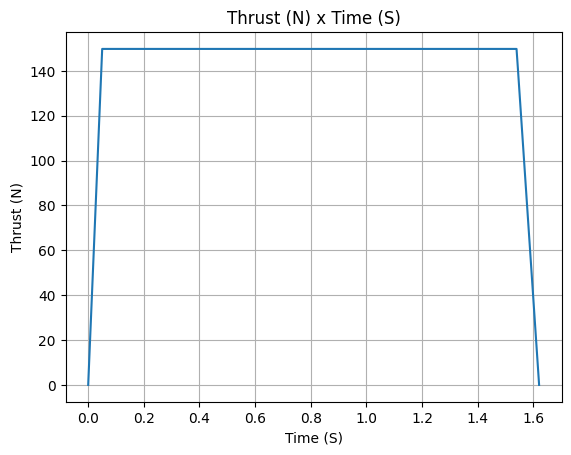

In [35]:
from rocketpy import SolidMotor

# Longitud estimada de la tobera para ubicarla geométricamente
longitud_tobera_estimada = 0.04  # ~40 mm

# Inicialización correcta sin argumentos inexistentes
KNSB_Motor = SolidMotor(
    thrust_source="curva_knsb.csv",
    dry_mass=0.600,  # Masa del motor vacío (sin propelente) [kg]
    dry_inertia=(0.05, 0.05, 0.001),  # (Ixx, Iyy, Izz) [kg*m^2]
    nozzle_radius=D_throat / 2.0,  # Radio de garganta [m]
    grain_number=NUM_GRANOS,  # Número de granos BATES (3)
    grain_density=RHO_P,  # Densidad KNSB (1780 kg/m^3)
    grain_outer_radius=D_EXT / 2.0,  # Radio exterior del grano [m]
    grain_initial_inner_radius=D_CORE / 2.0,  # Radio del canal central [m]
    grain_initial_height=L_GRANO,  # Longitud del segmento [m]
    grain_separation=0.001,  # Separación entre granos [m] (1 mm)
    grains_center_of_mass_position=0.10,  # Posición CM granos desde la tobera [m]
    center_of_dry_mass_position=0.10,  # Posición CM masa seca [m]
    nozzle_position=0.0,  # Posición de la tobera (origen en 0.0 m)
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

# Visualizar toda la información balística procesada por RocketPy
print(f"Impulso Total: {KNSB_Motor.total_impulse:.2f} Ns")
isp = KNSB_Motor.total_impulse / (KNSB_Motor.propellant_initial_mass * 9.80665)
print(f"Impulso Específico: {isp:.2f} s")
print(f"Masa de Propelente: {KNSB_Motor.propellant_initial_mass:.3f} kg")

# Graficar curvas de empuje y masa
KNSB_Motor.info()

RESULTADOS DEL VUELO (Masa seca: 1.54 kg)
Apogeo (Altitud máxima alcanzada): 568.21 m
Velocidad Máxima                : 119.25 m/s (429.3 km/h)
Tiempo hasta el apogeo          : 10.77 s
Tiempo de fin de quemado        : 1.62 s


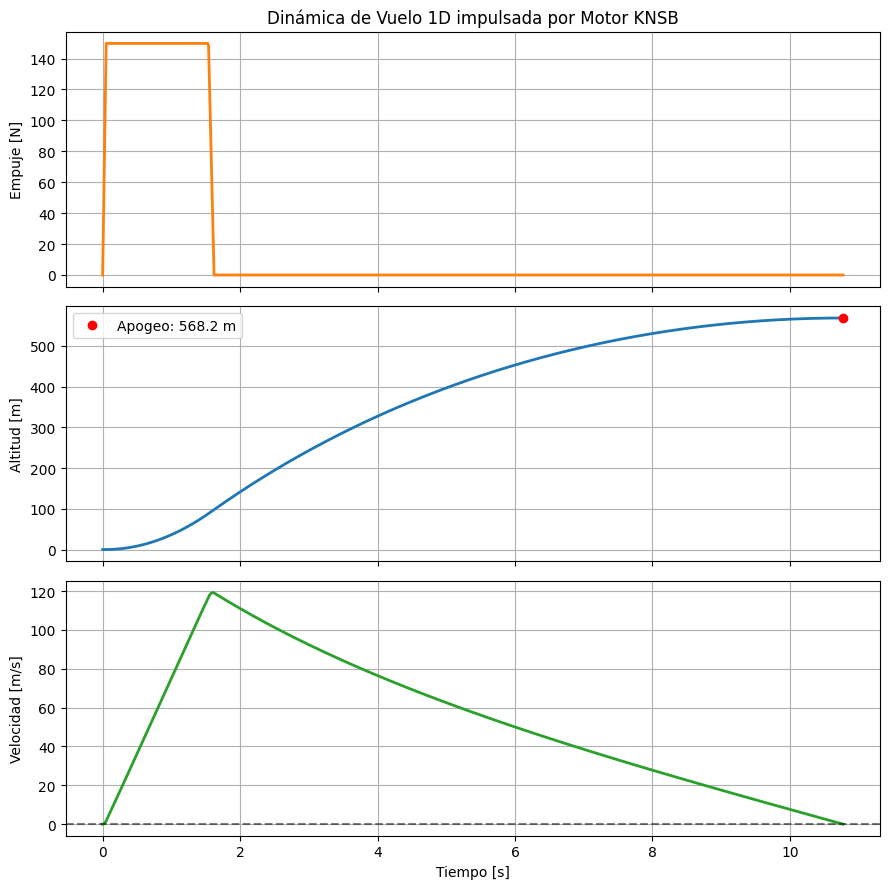

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==============================================================================
# 1. PARÁMETROS DEL SISTEMA
# ==============================================================================
# Masa seca del objeto/cohete (sin contar el propelente que se consume)
MASA_OBJETO = 1.538  # [kg]

# Constantes físicas y ambientales
G0 = 9.80665  # Gravedad [m/s^2]
RHO_AIRE = 1.225  # Densidad del aire al nivel del mar [kg/m^3]

# Parámetros aerodinámicos básicos (aproximación cilindro/cono)
DIAMETRO_CUERPO = 0.078  # 50 mm [m]
AREA_FRONTAL = np.pi * (DIAMETRO_CUERPO / 2.0) ** 2
CD = 0.45  # Coeficiente de resistencia aerodinámica típico para cohete subsónico


# ==============================================================================
# 2. DEFINICIÓN DE LAS ECUACIONES DE MOVIMIENTO (1D VERTICAL)
# ==============================================================================
def derivadas(t, y):
    """y[0] = posicion (altura z) [m]

    y[1] = velocidad (v) [m/s]
    """
    posicion = y[0]
    velocidad = y[1]

    # 1. Empuje instantáneo desde el motor de RocketPy
    empuje = float(KNSB_Motor.thrust(t))

    # 2. Masa instantánea (Masa del objeto + masa del propelente restante)
    masa_total = MASA_OBJETO + float(KNSB_Motor.propellant_mass(t))

    # 3. Fuerza de arrastre aerodinámico (Drag)
    fuerza_drag = (
        0.5
        * RHO_AIRE
        * (velocidad**2)
        * CD
        * AREA_FRONTAL
        * np.sign(velocidad)
    )

    # 4. Aceleración neta
    # Mientras el objeto esté en la rampa/suelo (z=0) y el empuje no supere el peso:
    if posicion <= 0.0 and (empuje - masa_total * G0) <= 0.0:
        aceleracion = 0.0
        velocidad = 0.0
    else:
        aceleracion = (empuje - fuerza_drag) / masa_total - G0

    return [velocidad, aceleracion]


def evento_apogeo(t, y):
    # Solo activamos la detección cuando ya pasó el tiempo de quemado
    if t > KNSB_Motor.burn_out_time:
        return y[1]  # Se activa cuando la velocidad cruza por cero hacia abajo
    return 1.0  # Mantiene un valor positivo arbitrario durante el ascenso


evento_apogeo.direction = -1  # Solo cuando va cayendo (de positivo a negativo)
evento_apogeo.terminal = (
    True  # Detiene la simulación al alcanzar la altura máxima
)

evento_apogeo.direction = -1  # Solo cuando va cayendo
evento_apogeo.terminal = True  # Detener simulación al llegar al punto más alto

# ==============================================================================
# 3. INTEGRACIÓN NUMÉRICA
# ==============================================================================
t_span = (0, 30.0)  # Simular hasta 30 segundos
y0 = [0.0, 0.0]  # Posición inicial = 0 m, Velocidad inicial = 0 m/s

sol = solve_ivp(
    derivadas,
    t_span,
    y0,
    events=evento_apogeo,
    max_step=0.01,
    method="RK45",
)

# Extraer resultados
tiempo = sol.t
altura = sol.y[0]
velocidad = sol.y[1]

apogeo = np.max(altura)
v_max = np.max(velocidad)
t_apogeo = tiempo[-1]

print("=" * 50)
print(f"RESULTADOS DEL VUELO (Masa seca: {MASA_OBJETO:.2f} kg)")
print("=" * 50)
print(f"Apogeo (Altitud máxima alcanzada): {apogeo:.2f} m")
print(f"Velocidad Máxima                : {v_max:.2f} m/s ({v_max*3.6:.1f} km/h)")
print(f"Tiempo hasta el apogeo          : {t_apogeo:.2f} s")
print(f"Tiempo de fin de quemado        : {KNSB_Motor.burn_out_time:.2f} s")
print("=" * 50)

# ==============================================================================
# 4. GRÁFICAS DE TRAYECTORIA
# ==============================================================================
fig, axs = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

# Curva de Empuje del Motor
empuje_t = [float(KNSB_Motor.thrust(t)) for t in tiempo]
axs[0].plot(tiempo, empuje_t, color="tab:orange", lw=2)
axs[0].set_ylabel("Empuje [N]")
axs[0].grid(True)
axs[0].set_title("Dinámica de Vuelo 1D impulsada por Motor KNSB")

# Altura recorrida
axs[1].plot(tiempo, altura, color="tab:blue", lw=2)
axs[1].plot(t_apogeo, apogeo, "ro", label=f"Apogeo: {apogeo:.1f} m")
axs[1].set_ylabel("Altitud [m]")
axs[1].legend()
axs[1].grid(True)

# Velocidad
axs[2].plot(tiempo, velocidad, color="tab:green", lw=2)
axs[2].axhline(0, color="black", linestyle="--", alpha=0.5)
axs[2].set_ylabel("Velocidad [m/s]")
axs[2].set_xlabel("Tiempo [s]")
axs[2].grid(True)

plt.tight_layout()
plt.show()